State stores the information that can be accessed by any of the nodes of the Graph 

Maintaing the context of the state at every node 

In [21]:
from typing import Annotated 
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END  # Elements of LangGraph 
from langgraph.graph.message import add_messages  

# add_messages is reducer 
# reducers -> Appending the results by the chatbot so that we can maintain the state of the converstaion 
# we are not replacing things but appending in the form of a list (for add_messages)

In [22]:
class State(TypedDict):
    messages : Annotated[list, add_messages]  # list of messages in the conversation

graph_builder = StateGraph(State)  # StateGraph is a class that takes a TypedDict as input and creates a graph of states

In [23]:
graph_builder 

In [24]:
import os
from dotenv import load_dotenv
load_dotenv()  # Load environment variables from .env file

True

In [25]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002545512DD10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002545512E710>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

For every node we need to write a node definition 

In [26]:
# Node Functionality
def chatbot(state: State):
    return {"messages":[llm.invoke(state["messages"])]}

In [27]:
graph_builder = StateGraph(State)
graph_builder.add_node("llmchatbot", chatbot) # Added Node 

# Creating Edges 
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## Compilation of Graph 
graph = graph_builder.compile()

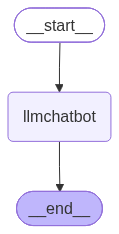

In [28]:
# Visualize Graph 
from IPython.display import Image, display 

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [30]:
response = graph.invoke({"messages":"Hi"}) # As it its taking from the state and from the key messages 

In [33]:
response["messages"][-1].content # This appending of Messages if done by reducers 

'Hello! How can I help you today?'

In [38]:
for event in graph.stream({"messages":"Hi how are you"}):
    for value in event.values(): # Capturing on AI Messages 
        print(value["messages"][-1].content)

Hello! I'm doing great, thank you for asking. How can I help you today?


In [37]:
graph.invoke({"messages":"What is Python?"})

{'messages': [HumanMessage(content='What is Python?', additional_kwargs={}, response_metadata={}, id='ed0131c3-38f9-4d8e-a6b9-36e9fa2dd5c4'),
  AIMessage(content='**Python** is a high‑level, interpreted programming language known for its readability and flexibility. It was created by\u202fGuido van\u202fRossum and first released in\u202f1991. Here are the key characteristics that define Python:\n\n| Feature | What it means |\n|---------|----------------|\n| **Readability** | Uses indentation to define code blocks, making the syntax clean and easy to understand. |\n| **Interpreted** | Code is executed line‑by‑line by the Python interpreter, so you don’t need a separate compilation step. |\n| **Dynamically typed** | Variable types are inferred at runtime; you don’t declare them explicitly. |\n| **Multi‑paradigm** | Supports procedural, object‑oriented, functional, and even some aspects of aspect‑oriented programming. |\n| **Extensive standard library** | “Batteries‑included” modules for 

In [ ]:
"""
The add_messages reducer only appends inside a single run. 
It adds the AI reply to the messages you passed in, but it doesn’t store anything between separate invoke calls.
"""